In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyvista as pv
from desmin_reconstruction.plotting import line_and_bandplot, save_panel
from desmin_reconstruction.plotting.overlays import compose_overlays, render_overlays
from desmin_reconstruction.plotting.renderings import (
    render_pointcloud,
)
from desmin_reconstruction.utils.array import find_crossing_points
from IPython.display import display, SVG


plt.rc("font", size=12)
plt.rc("grid", linestyle="--", color="lightgray")
plt.rc("axes.spines", right=False, top=False)
pv.set_jupyter_backend("static")

COLOR_DICT = {"desmin": "#CC3311", "alpha_actinin": "#009988", "actin": "#0077BB"}

datadir = Path("../../data/")

In [ ]:
def plot_voronoi_distributions(
    npz_path,
    names,
    *,
    line_and_bandplot,
    find_crossing_points,
    n_bins=4000,
    percentile=97.5,
    xlims=None,
    ylims=None,
    figsize=(4.5, 6),
    colors=None,
    titles=None,
    legend_loc="upper right",
):
    """Plot each protein's PDF and the mean +/- SD of randomized PDFs.

    Parameters
    ----------
    npz_path : path-like
        NPZ containing ``name`` and ``name_random`` for each entry in names.
        Axis 0 of name_random indexes independent random realizations;
        all remaining dimensions of each realization are flattened.
    names : sequence of str
        NPZ keys, in panel order; e.g. ('desmin', 'alpha_actinin').
    line_and_bandplot, find_crossing_points : callable
        Existing helpers from the notebook. The threshold remains exactly
        find_crossing_points(bin_centers, counts, random_mean)[0][0].
    n_bins : int
        Number of bins covering values at or below the pooled percentile.
        One additional tail bin extends to the overall maximum if needed.
    xlims, ylims : dict, optional
        Per-protein limits, e.g. {'desmin': (0, 0.04)}. Omitted entries autoscale.
    colors, titles : dict, optional
        Overrides for the designated protein colors and display names.
        'alpha_actinin' inherits the 'actinin' color unless explicitly provided.
    save_path : path-like, optional
        Save to this filename, including its extension. Otherwise do not save.

    Returns
    -------
    fig, axes, vol_thresholds
        axes is always a flat array; vol_thresholds is a list in names order.
        The figure remains open for display, annotation, or further export.

    Nonfinite volumes are excluded. Every observed sample and random
    realization must contain at least one finite volume. Standard deviations
    use ddof=0, matching np.std in the original code.
    """
    names = tuple(names)
    if not names or len(set(names)) != len(names):
        raise ValueError("names must be a nonempty sequence of distinct keys.")
    if not isinstance(n_bins, (int, np.integer)) or n_bins < 1:
        raise ValueError("n_bins must be a positive integer.")
    if not 0 < percentile <= 100:
        raise ValueError("percentile must be in (0, 100].")

    palette = {
        "desmin": "#CC3311",
        "actin": "#0077BB",
        "actinin": "#009988",
        "myosin": "#BBBBBB",
        **(colors or {}),
    }
    palette.setdefault("alpha_actinin", palette["actinin"])
    labels = {
        "desmin": "Desmin",
        "actin": "Actin",
        "actinin": "α-actinin",
        "alpha_actinin": "α-actinin",
        "myosin": "Myosin",
        **(titles or {}),
    }
    xlims, ylims = xlims or {}, ylims or {}
    series = []
    vol_thresholds = []

    # Calculate everything before opening the figure, including thresholds.
    with np.load(npz_path) as volumes:
        for name in names:
            observed = np.asarray(volumes[name], dtype=float).ravel()
            observed = observed[np.isfinite(observed)]
            random = np.asarray(volumes[f"{name}_random"], dtype=float)
            if random.ndim < 2 or len(random) == 0:
                raise ValueError(f"{name}_random must have realizations along axis 0.")
            realizations = [v[np.isfinite(v)] for v in random.reshape(len(random), -1)]
            if observed.size == 0 or any(v.size == 0 for v in realizations):
                raise ValueError(
                    f"{name}: observed data and each realization need finite volumes."
                )

            pooled = np.concatenate([observed, *realizations])
            cutoff = np.percentile(pooled, percentile)
            edges = np.histogram_bin_edges(pooled[pooled <= cutoff], bins=n_bins)
            # Avoid adding a duplicate edge (and a zero-width tail bin).
            if pooled.max() > edges[-1]:
                edges = np.append(edges, pooled.max())

            centers = (edges[:-1] + edges[1:]) / 2
            counts = np.histogram(observed, edges, density=True)[0]
            random_counts = np.stack(
                [np.histogram(v, edges, density=True)[0] for v in realizations]
            )
            random_mean = np.mean(random_counts, axis=0)
            random_std = np.std(random_counts, axis=0)
            try:
                threshold = find_crossing_points(centers, counts, random_mean)[0][0]
            except IndexError as error:
                raise ValueError(f"{name}: no crossing point was returned.") from error
            vol_thresholds.append(threshold)
            series.append((centers, counts, random_mean, random_std, threshold))

    fig, axes = plt.subplots(
        len(names),
        1,
        figsize=figsize,
        squeeze=False,
        constrained_layout=True,
        gridspec_kw={"wspace": 0.1},
    )
    axes = axes[:, 0]
    try:
        for ax, name, (centers, counts, random_mean, random_std, threshold) in zip(
            axes, names, series
        ):
            ax.plot(centers, counts, alpha=0.9, color=palette[name], label=labels[name])
            line_and_bandplot(
                ax,
                centers,
                random_mean,
                random_std,
                color="black",
                alpha=0.7,
                label="Uniform random",
            )
            ax.set_yscale("log")
            ax.axvline(threshold, linestyle="--", color="brown", label="Threshold")
            ax.grid(ls="--", color="lightgray")
            if name in xlims:
                ax.set_xlim(xlims[name])
            if name in ylims:
                ax.set_ylim(ylims[name])

        # One legend, ordered as proteins, random reference, threshold.
        handles_by_label = {}
        for ax in axes:
            handles, legend_labels = ax.get_legend_handles_labels()
            handles_by_label.update(zip(legend_labels, handles))
        order = [labels[name] for name in names] + ["Uniform random", "Threshold"]
        axes[0].legend(
            [handles_by_label[label] for label in order], order, loc=legend_loc
        )
        fig.supxlabel("Voronoi cell volume (μm³)", fontsize="large")
        fig.supylabel("Probability Density Function", fontsize="large")

    except Exception:
        plt.close(fig)
        raise

    return fig, axes, vol_thresholds


voronoi_plot_kwargs = dict(
    line_and_bandplot=line_and_bandplot,
    find_crossing_points=find_crossing_points,
    colors=COLOR_DICT,
    figsize=(4.5, 6),
    percentile=97.5,
)

## S2a. Original dSTORM thin section for desmin/alpha-actinin

In [3]:
df = pl.read_csv("../../data/STORM/desmin_alphaactinin_600nm.csv")
df = df.with_columns(*[pl.col(i) / 1000 for i in ("x", "y", "z")])
df = df.with_columns(*[pl.col(i) - pl.col(i).min() for i in ("x", "y", "z")])
points = {
    name: df_.select(["x", "y", "z"]).to_numpy()
    for name, df_ in zip(("desmin", "alpha_actinin"), df.partition_by("probe"))
}


2026-09-28 17:01:09.569 (   8.725s) [    1464DC7E6740]vtkXOpenGLRenderWindow.:1416  WARN| bad X server connection. DISPLAY=


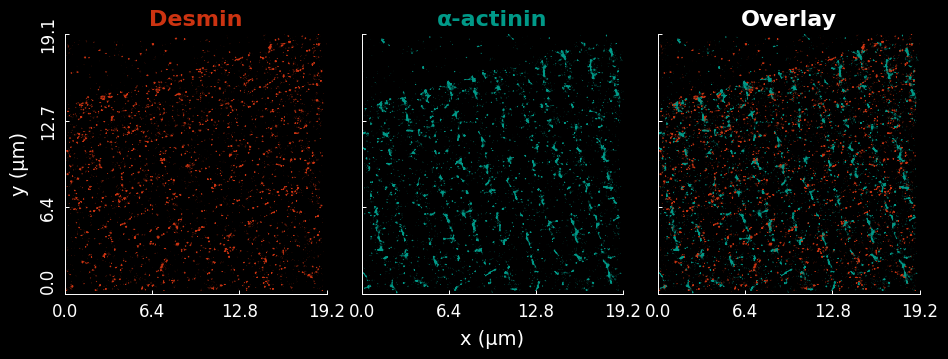

In [ ]:
rendered = render_overlays(
    points,
    COLOR_DICT,
    render_pointcloud,
    protein_names=("desmin", "alpha_actinin"),
    xy_bounds=None,  # Common bounds from both point clouds
    height_px=700,
    opacity=0.2,
    point_size=1.0,
)

fig, axes = compose_overlays(
    rendered,
    titles=("Desmin", "α-actinin", "Overlay"),
    panel_height=2.6,  # Inches
    panel_gap=0.35,  # Horizontal gap between panels, inches
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=12,
    ytick_fontsize=12,
    title_fontsize=16,
    xtick_pad=6,  # All padding below is in points
    ytick_pad=6,
    xlabel_pad=7,  # Smaller = common X title closer to panels
    ylabel_pad=7,
    ytick_rotation=90,
    tick_format="%.1f",
)


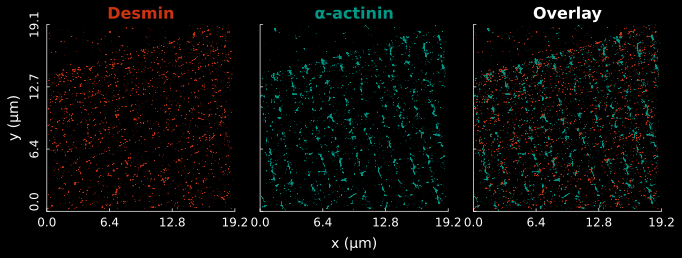

In [6]:
savepath = "../../figures/S2a"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)

## S2c. Voronoi cell volume histogram for threshold determination (desmin/alpha-actinin)

In [16]:
fig_aa, axes_aa, thresholds_aa = plot_voronoi_distributions(
    datadir / "results/desmin_alphaactinin_600nm_voronoi_volumes.npz",
    names=("desmin", "alpha_actinin"),
    n_bins=4000,
    xlims={
        "desmin": (0, 0.04),
        "alpha_actinin": (0, 0.04),
    },
    ylims={
        "desmin": (5e-1, 1e3),
        "alpha_actinin": (1e-1, 1e3),
    },
    **voronoi_plot_kwargs,
)

/home/jhko725/projects/desmin_reconstruction/src/desmin_reconstruction/utils/array.py:27: RuntimeWarning: invalid value encountered in divide
  return (y1 * x2 + y2 * x1) / (y1 + y2)


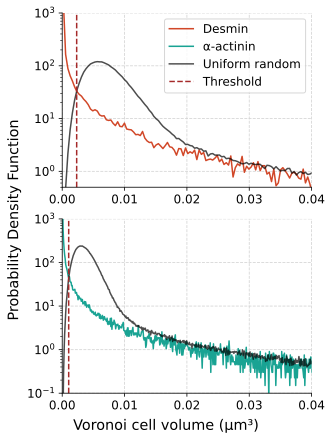

In [18]:
savepath = "../../figures/S2c"
save_panel(fig_aa, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig_aa)

## S2d. Original dSTORM thin section for desmin/actin

In [ ]:
filepath = datadir / "STORM/actin_desmin_600nm.csv"
df = pl.read_csv(filepath)
df = df.with_columns(*[pl.col(i) / 1000 for i in ("x", "y", "z")])
df = df.with_columns(*[pl.col(i) - pl.col(i).min() for i in ("x", "y", "z")])
points = {
    name: df_.select(["x", "y", "z"]).to_numpy()
    for name, df_ in zip(("actin", "desmin"), df.partition_by("probe"))
}

In [ ]:
rendered = render_overlays(
    points,
    COLOR_DICT,
    render_pointcloud,
    protein_names=("desmin", "actin"),
    xy_bounds=None,  # Common bounds from both point clouds
    height_px=700,
    opacity=0.2,
    point_size=1.0,
)

fig, axes = compose_overlays(
    rendered,
    titles=("Desmin", "Actin", "Overlay"),
    panel_height=2.6,  # Inches
    panel_gap=0.35,  # Horizontal gap between panels, inches
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=12,
    ytick_fontsize=12,
    title_fontsize=16,
    xtick_pad=6,  # All padding below is in points
    ytick_pad=6,
    xlabel_pad=7,  # Smaller = common X title closer to panels
    ylabel_pad=7,
    ytick_rotation=90,
    tick_format="%.1f",
)


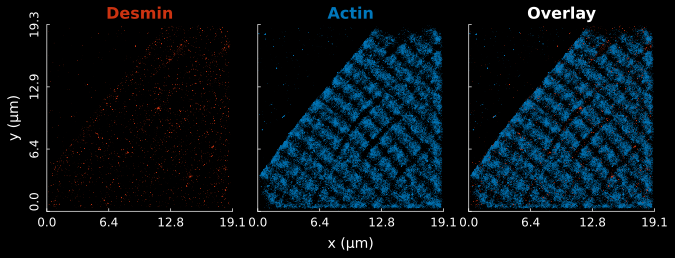

In [12]:
savepath = "../../figures/S2d"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)

## S2f. Voronoi cell volume histogram for threshold determination (desmin/actin)

In [21]:
fig_actin, axes_actin, thresholds_actin = plot_voronoi_distributions(
    datadir / "results/actin_desmin_600nm_voronoi_volumes.npz",
    names=("desmin", "actin"),
    n_bins=5000,
    xlims={
        "desmin": (0, 0.5),
        "actin": (0, 0.02),
    },
    ylims={
        "desmin": (1e-2, 1e3),
        "actin": (5e-2, 1e5),
    },
    **voronoi_plot_kwargs,
)

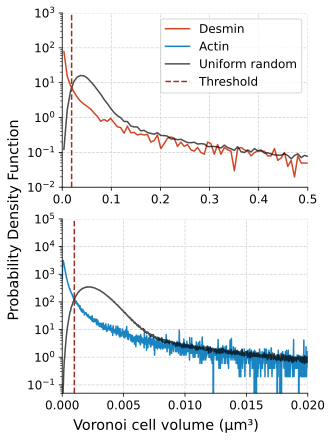

In [22]:
savepath = "../../figures/S2f"
save_panel(fig_actin, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig_actin)